# Data analysis, experiment 1

In [1]:
!source ../.venv/bin/activate

import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from matplotlib import rc
import matplotlib

matplotlib.rcParams['savefig.transparent'] = False

from lmfocus.results import gather_data_accuracy
from lmfocus.utils import (
    MODEL_NAME_MAPPING,
    GEMMA_MODELS,
    QWEN_3_MODELS,
    QWEN_35_MODELS,
    MODEL_SIZES,
    TestType,
    DATA_TYPE_TRANSLATION,
    CATEGORY_TRANSLATION,
    FM_TRANSLATION,
    METHODS_PALETTE,
    RANDOM_FOCUS_MARKERS
)

results_folder = "../data/results"

sns.set_theme(font='Cronos Pro', style='whitegrid', palette='deep')
plt.subplots_adjust(hspace = 0.1)

<Figure size 640x480 with 0 Axes>

## Gather data for original and revised datasets into two dataframes

In [2]:
gemma_data_standard = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
)

gemma_data_random = gather_data_accuracy(
    models = GEMMA_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_3_data_standard = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2
)

qwen_3_data_random = gather_data_accuracy(
    models = QWEN_3_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

qwen_35_data_standard = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2
)

qwen_35_data_random = gather_data_accuracy(
    models = QWEN_35_MODELS,
    results_folder = results_folder,
    dataset = 2,
    focus_markers = RANDOM_FOCUS_MARKERS
)

gemma_data_standard['fm_type'] = 'Standard'
qwen_3_data_standard['fm_type'] = 'Standard'
qwen_35_data_standard['fm_type'] = 'Standard'

gemma_data_random['fm_type'] = 'Ad Hoc'
qwen_3_data_random['fm_type'] = 'Ad Hoc'
qwen_35_data_random['fm_type'] = 'Ad Hoc'

data = pd.concat([
    gemma_data_standard,
    gemma_data_random,
    qwen_3_data_standard,
    qwen_3_data_random,
    qwen_35_data_standard,
    qwen_35_data_random
])

In [3]:
data.shape

(431460, 8)

## Graph method comparison

In [4]:
def model_to_model_family(model_name: str):
    if model_name.startswith('gemma'):
        return 'Gemma 4'
    elif model_name.startswith('qwen_3.5'):
        return 'Qwen3.5'
    else:
        return 'Qwen3'

In [5]:
data['Method'] = data['data_type'].apply(lambda x: DATA_TYPE_TRANSLATION[x])
data['model_size'] = data['model'].apply(lambda x: MODEL_SIZES[x])
data['model_family'] = data['model'].apply(model_to_model_family)

In [6]:
data.head()

,original_data_index,correct,focus_marker,data_type,category,model,condition,fm_type,Method,model_size,model_family
0,0,False,all_caps,string_probs,ONLY,gemma_4_E2B,Target,Standard,SP,2.0,Gemma 4
1,1,True,all_caps,string_probs,ONLY,gemma_4_E2B,Target,Standard,SP,2.0,Gemma 4
2,2,True,all_caps,string_probs,ONLY,gemma_4_E2B,Target,Standard,SP,2.0,Gemma 4
3,3,True,all_caps,string_probs,ONLY,gemma_4_E2B,Target,Standard,SP,2.0,Gemma 4
4,4,False,all_caps,string_probs,ONLY,gemma_4_E2B,Target,Standard,SP,2.0,Gemma 4


In [43]:
def method_comp_plot(model_family: str, include_legend: bool = True, height=2.5, aspect=1.8, legendalpha=1):
    sub_data = data.copy()
    sub_data = sub_data[sub_data['model_family'] == model_family]
    g = sns.catplot(
        data=sub_data,
        hue='Method',
        hue_order=['YN2', 'YN1', 'FC2', 'FC1', 'SP'],
        y='correct',
        x='model_size',
        kind='point',
        col='fm_type',
        col_order = ['Standard', 'Ad Hoc'],
        native_scale=True,
        palette=METHODS_PALETTE,
        estimator=lambda x: (sum(x) / len(x)) * 100,
        col_wrap=2,
        height=height,
        aspect=aspect
    )

    g.set_titles('{col_name}', fontsize=18)
    
    for ax in g.axes.flat:
        ax.grid(axis='x', visible=False)
        # ax.set_xticks(data['model_size'].unique())
        ax.set_ylim(top=100)
        ax.set_title(ax.get_title(), fontsize=18)
        ax.set_xlabel('Parameters (Billions)', fontsize=18)
        ax.set_ylabel('Accuracy (%)', fontsize=18)
        ax.axhline(
            50,
            linestyle=':',
            color='black',
            linewidth=1.5,
        )
        ax.set_xscale('log')
        ax.minorticks_off()
        x_ticks = sorted(sub_data['model_size'].dropna().unique())

        ax.set_xticks(x_ticks)
        ax.set_xticklabels([
            f'{x:g}' for x in x_ticks
        ])
        for line in ax.lines:
            line.set_linewidth(1.5)
            line.set_markersize(2)
    
    legend = g.legend
    
    # Get its handles and labels
    handles = list(reversed(legend.legend_handles))
    # handles = [handles[0], handles[3], handles[1], handles[4], handles[2]]
    labels = list(reversed([text.get_text() for text in legend.texts]))
    # labels = [labels[0], labels[3], labels[1], labels[4], labels[2]]
    
    # Add chance line
    handles.append(
        Line2D(
            [0], [0],
            color='black',
            linestyle=':',
            linewidth=1.5
        )
    )
    labels.append('Chance')
    
    # Remove old legend
    legend.remove()
    
    # Recreate it
    if include_legend:
        g.figure.legend(
            handles=handles,
            labels=labels,
            title='',
            bbox_to_anchor = (0.5, -.15),
            loc='lower center',
            ncols = 6,
            framealpha = legendalpha
        )
    g.figure.suptitle(model_family, y=1.03, fontsize=24)

    # g.set_xticklabels(rotation=-45)
    return g

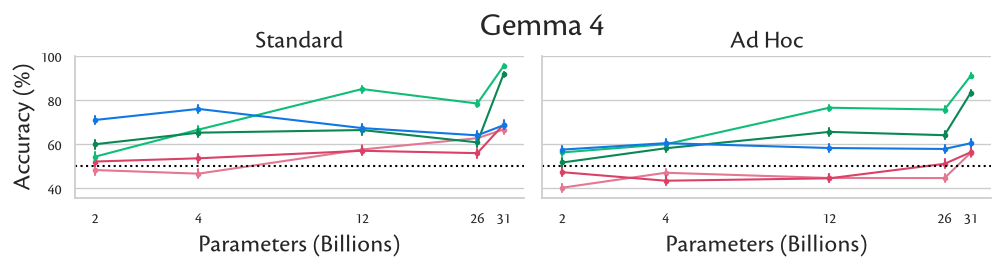

In [44]:
gemma_plot_method_comp = method_comp_plot("Gemma 4", include_legend=False, aspect=2)
gemma_plot_method_comp.savefig('../graphs/POSTER_01a_gemma_exps_comp.png')

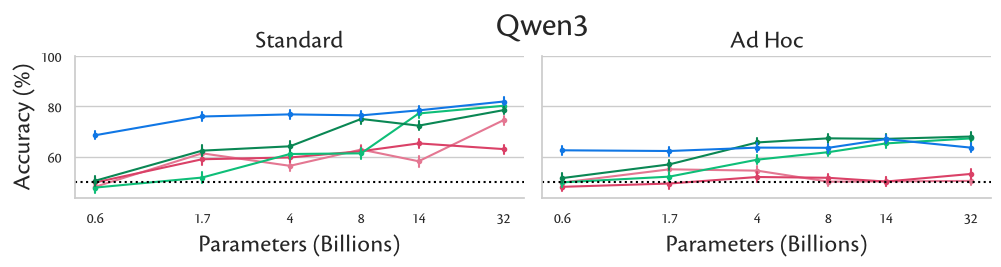

In [45]:
qwen_3_plot_method_comp = method_comp_plot("Qwen3", include_legend=False, aspect = 2)
qwen_3_plot_method_comp.savefig('../graphs/POSTER_01b_qwen3_exps_comp.png')

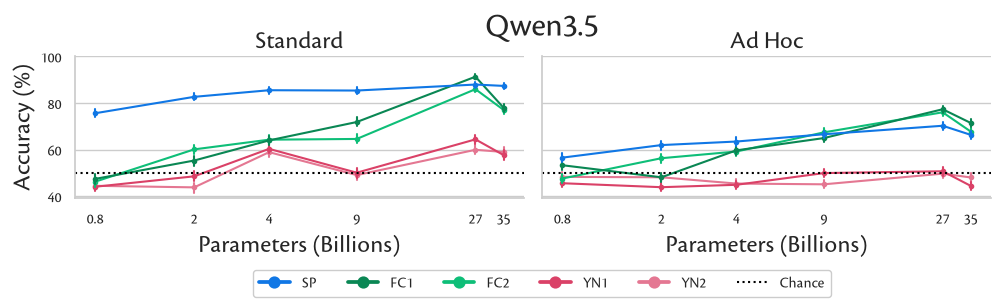

In [46]:
qwen_35_plot_method_comp = method_comp_plot("Qwen3.5", aspect=2)
qwen_35_plot_method_comp.savefig('../graphs/POSTER_01c_qwen35_exps_comp.png')